<a href="https://colab.research.google.com/github/kunwar1908/Cognitive-Computing-UCS420/blob/main/Assignment_8_NLP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# UCS420 Cognitive Computing - Lab Assignment 10
## Assignment Title: NLP using Python-II
**(Feature extraction from text, sentiment analysis and text generation)**

In [ ]:
# Step 0: Initial Setup and Downloads
import nltk
import re
import string
import numpy as np
import matplotlib.pyplot as plt

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')
nltk.download('vader_lexicon')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data] Downloading package vader_lexicon to /root/nltk_data...


True

---
### Q1: Text Preprocessing, Tokenization, and Frequency Distribution
**Tasks:**
1. Convert text to lowercase and remove punctuation using `re`.
2. Tokenize text into words and sentences.
3. Split using `split()` and `word_tokenize()` and compare differences.
4. Remove stopwords (using NLTK's stopwords list).
5. Display word frequency distribution (excluding stopwords).

--- Original Paragraph ---
Artificial intelligence is transforming every modern industry across the globe. Machine learning models analyze complex patterns from massive datasets with remarkable precision. Autonomous systems and neural networks are enabling rapid scientific breakthroughs. However, ethical considerations and algorithmic biases require strict scrutiny from researchers. Responsible innovation ensures that intelligent automation benefits human society fairly.

--- Cleaned Paragraph (Lowercase + No Punctuation) ---
artificial intelligence is transforming every modern industry across the globe machine learning models analyze complex patterns from massive datasets with remarkable precision autonomous systems and neural networks are enabling rapid scientific breakthroughs however ethical considerations and algorithmic biases require strict scrutiny from researchers responsible innovation ensures that intelligent automation benefits human society fairly

Sentence Count: 5
Senten

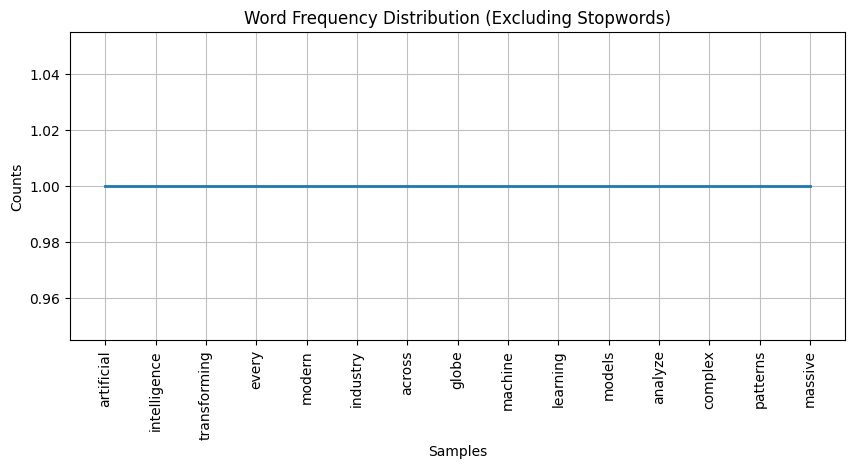

In [ ]:
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from nltk.probability import FreqDist

# Chosen Paragraph (Technology / Artificial Intelligence)
paragraph = (
    "Artificial intelligence is transforming every modern industry across the globe. "
    "Machine learning models analyze complex patterns from massive datasets with remarkable precision. "
    "Autonomous systems and neural networks are enabling rapid scientific breakthroughs. "
    "However, ethical considerations and algorithmic biases require strict scrutiny from researchers. "
    "Responsible innovation ensures that intelligent automation benefits human society fairly."
)

print("--- Original Paragraph ---")
print(paragraph)

# 1. Convert to lowercase and remove punctuation using re
clean_para = paragraph.lower()
clean_para_no_punct = re.sub(r'[^\w\s]', '', clean_para)
print("\n--- Cleaned Paragraph (Lowercase + No Punctuation) ---")
print(clean_para_no_punct)

# 2. Tokenize into words and sentences
sentences = sent_tokenize(paragraph)
words_from_clean = word_tokenize(clean_para_no_punct)
print(f"\nSentence Count: {len(sentences)}")
print("Sentences:", sentences)

# 3. Compare split() vs word_tokenize() on original paragraph
py_split = paragraph.split()
nltk_tokens = word_tokenize(paragraph)
print(f"\nPython split() count: {len(py_split)}")
print("First 10 split() tokens:", py_split[:10])
print(f"\nNLTK word_tokenize() count: {len(nltk_tokens)}")
print("First 10 word_tokenize() tokens:", nltk_tokens[:10])

# Explanation of difference:
print("\n[Comparison] Python split() splits purely on whitespace, leaving punctuation attached to words (e.g. 'globe.'). NLTK word_tokenize() uses linguistic rules (Treebank tokenizer) to isolate punctuation as separate tokens.")

# 4. Remove stopwords
stop_words = set(stopwords.words('english'))
filtered_words = [w for w in words_from_clean if w not in stop_words]
print(f"\nWords before stopword removal: {len(words_from_clean)}")
print(f"Words after stopword removal: {len(filtered_words)}")
print("Filtered words:", filtered_words)

# 5. Display word frequency distribution
fdist = FreqDist(filtered_words)
print("\n--- Word Frequency Distribution (Top 10) ---")
for word, count in fdist.most_common(10):
    print(f"{word}: {count}")

# Plotting frequency distribution
plt.figure(figsize=(10, 4))
fdist.plot(15, title="Word Frequency Distribution (Excluding Stopwords)")
plt.show()

---
### Q2: Stemming vs. Lemmatization
**Tasks:**
1. Extract all words with only alphabets using `re.findall()`
2. Remove stop words using NLTK's stopword list
3. Perform stemming with `PorterStemmer`
4. Perform lemmatization with `WordNetLemmatizer`
5. Compare outputs and explain when to prefer which.

In [ ]:
from nltk.stem import PorterStemmer, WordNetLemmatizer
import pandas as pd

# 1. Extract only alphabetic words using re.findall
alpha_words = re.findall(r'\b[a-zA-Z]+\b', paragraph.lower())

# 2. Remove stopwords
stop_words = set(stopwords.words('english'))
filtered_alpha = [w for w in alpha_words if w not in stop_words]

# 3. Stemming
stemmer = PorterStemmer()
stemmed_words = [stemmer.stem(w) for w in filtered_alpha]

# 4. Lemmatization
lemmatizer = WordNetLemmatizer()
lemmatized_words = [lemmatizer.lemmatize(w) for w in filtered_alpha]

# Comparison Table
comp_df = pd.DataFrame({
    'Original Word': filtered_alpha,
    'Porter Stemmer': stemmed_words,
    'WordNet Lemmatizer': lemmatized_words
})

print("--- Comparison Table (First 15 Words) ---")
print(comp_df.head(15).to_string(index=False))

# Highlight Differences
diff_df = comp_df[comp_df['Porter Stemmer'] != comp_df['WordNet Lemmatizer']]
print("\n--- Differences between Stemming and Lemmatization ---")
print(diff_df.to_string(index=False))

comparison_explanation = """
Key Comparison & When to Prefer:
1. Porter Stemmer cuts word affixes using crude heuristic rules. It is computationally fast but often creates non-dictionary roots (e.g., 'society' -> 'societi', 'responsible' -> 'respons').
2. WordNet Lemmatizer uses lexical morphological analysis and vocabulary lookups to return valid dictionary headwords (lemmas) (e.g., 'considerations' -> 'consideration', 'biases' -> 'bias').
3. When to prefer Stemming: Large-scale information retrieval (search engines), spam filtering, fast text indexing where runtime speed is critical and root validity does not matter.
4. When to prefer Lemmatization: Semantic analysis, QA systems, chatbots, sentiment analysis, and summarization where grammatical accuracy, POS context, and human interpretability are essential.
"""
print(comparison_explanation)

--- Comparison Table (First 15 Words) ---
Original Word Porter Stemmer WordNet Lemmatizer
   artificial       artifici         artificial
 intelligence       intellig       intelligence
 transforming      transform       transforming
        every          everi              every
       modern         modern             modern
     industry       industri           industry
       across         across             across
        globe          globe              globe
      machine         machin            machine
     learning          learn           learning
       models          model              model
      analyze         analyz            analyze
      complex        complex            complex
     patterns        pattern            pattern
      massive         massiv            massive

--- Differences between Stemming and Lemmatization ---
 Original Word Porter Stemmer WordNet Lemmatizer
    artificial       artifici         artificial
  intelligence       intellig       

---
### Q3: Feature Extraction (CountVectorizer & TfidfVectorizer)
**Tasks:**
1. Use `CountVectorizer` to generate Bag of Words (BoW) representation.
2. Use `TfidfVectorizer` to compute TF-IDF scores.
3. Print and interpret the top 3 keywords from each text using TF-IDF.

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

# 3 Short Texts (News headlines / Product reviews)
texts = [
    "The electric vehicle market experiences unprecedented growth and record stock surge.",
    "Researchers discover breakthrough quantum computing algorithms for cryptographic security.",
    "The smartphone camera delivers outstanding portrait photography with remarkable battery life."
]

# 1. Bag of Words (CountVectorizer)
bow_vec = CountVectorizer(stop_words='english')
bow_matrix = bow_vec.fit_transform(texts)
bow_df = pd.DataFrame(bow_matrix.toarray(), columns=bow_vec.get_feature_names_out(), index=[f'Text {i+1}' for i in range(3)])
print("--- Bag of Words (CountVectorizer) Feature Matrix ---")
print(bow_df)

# 2. TF-IDF Representation
tfidf_vec = TfidfVectorizer(stop_words='english')
tfidf_matrix = tfidf_vec.fit_transform(texts)
feature_names = np.array(tfidf_vec.get_feature_names_out())
tfidf_df = pd.DataFrame(tfidf_matrix.toarray(), columns=feature_names, index=[f'Text {i+1}' for i in range(3)])
print("\n--- TF-IDF Matrix ---")
print(tfidf_df.round(3))

# 3. Top 3 keywords for each text
print("\n--- Top 3 Keywords per Text (TF-IDF) ---")
for i, text in enumerate(texts):
    row = tfidf_matrix.toarray()[i]
    top_indices = np.argsort(row)[::-1][:3]
    top_keywords = feature_names[top_indices]
    top_scores = row[top_indices]
    print(f"\nText {i+1}: \"{text}\"")
    for kw, score in zip(top_keywords, top_scores):
        print(f"  -> {kw} (TF-IDF: {score:.4f})")
    print("  Interpretation: Reflects core topical signature unique to this domain without noise words.")

--- Bag of Words (CountVectorizer) Feature Matrix ---
        algorithms  battery  breakthrough  camera  computing  cryptographic  \
Text 1           0        0             0       0          0              0   
Text 2           1        0             1       0          1              1   
Text 3           0        1             0       1          0              0   

        delivers  discover  electric  experiences  ...  quantum  record  \
Text 1         0         0         1            1  ...        0       1   
Text 2         0         1         0            0  ...        1       0   
Text 3         1         0         0            0  ...        0       0   

        remarkable  researchers  security  smartphone  stock  surge  \
Text 1           0            0         0           0      1      1   
Text 2           0            1         1           0      0      0   
Text 3           1            0         0           1      0      0   

        unprecedented  vehicle  
Text 1    

---
### Q4: Document Similarity (Jaccard vs Cosine Similarity)
**Tasks:**
1. Preprocess and tokenize two texts describing different technologies (AI vs Blockchain).
2. Calculate:
   - a. Jaccard Similarity using sets
   - b. Cosine Similarity using `TfidfVectorizer` + `cosine_similarity()`
   - c. Analyze which metric gives better insights.

In [ ]:
from sklearn.metrics.pairwise import cosine_similarity

ai_text = (
    "Artificial intelligence leverages neural networks and machine learning algorithms to automate complex tasks. "
    "It learns patterns from training datasets to make intelligent decisions and predictive forecasts. "
    "Modern AI models drive natural language processing, autonomous robotics, and computer vision systems. "
    "Continuous model optimization enhances cognitive capabilities across industrial applications."
)

blockchain_text = (
    "Blockchain is a decentralized distributed ledger technology that securely records transactions across nodes. "
    "It relies on cryptographic hashing and consensus mechanisms to ensure data immutability and trust. "
    "Smart contracts automatically execute agreements without intermediaries or central authorities. "
    "Modern enterprise networks utilize blockchain for transparent supply chain tracking and digital payments."
)

# 1. Preprocess and tokenize
def preprocess(text):
    cleaned = re.sub(r'[^a-zA-Z\s]', '', text.lower())
    tokens = word_tokenize(cleaned)
    return [w for w in tokens if w not in stop_words]

ai_tokens = preprocess(ai_text)
bc_tokens = preprocess(blockchain_text)

# 2a. Jaccard Similarity
set_ai = set(ai_tokens)
set_bc = set(bc_tokens)
intersection = set_ai.intersection(set_bc)
union = set_ai.union(set_bc)
jaccard_sim = len(intersection) / len(union)

print(f"Common words ({len(intersection)}):", intersection)
print(f"Total unique words across both ({len(union)})")
print(f"Jaccard Similarity: {jaccard_sim:.4f}")

# 2b. Cosine Similarity using TF-IDF
vectorizer = TfidfVectorizer(stop_words='english')
tfidf_sim_matrix = vectorizer.fit_transform([ai_text, blockchain_text])
cos_sim = cosine_similarity(tfidf_sim_matrix[0:1], tfidf_sim_matrix[1:2])[0][0]
print(f"Cosine Similarity: {cos_sim:.4f}")

# 2c. Metric Analysis
print("\n--- Analysis of Similarity Metrics ---")
print("Cosine Similarity gives better insights here. Jaccard treats all unique words as binary (present/absent) sets, discarding term frequencies and document specificity. In contrast, TF-IDF Cosine Similarity weights terms according to their importance (penalizing ubiquitous terms and rewarding domain-specific keywords), computing the directional angular distance between documents in vector space.")

Common words (3): {'networks', 'across', 'modern'}
Total unique words across both (76)
Jaccard Similarity: 0.0395
Cosine Similarity: 0.0263

--- Analysis of Similarity Metrics ---
Cosine Similarity gives better insights here. Jaccard treats all unique words as binary (present/absent) sets, discarding term frequencies and document specificity. In contrast, TF-IDF Cosine Similarity weights terms according to their importance (penalizing ubiquitous terms and rewarding domain-specific keywords), computing the directional angular distance between documents in vector space.


---
### Q5: Sentiment Analysis and WordCloud
**Tasks:**
1. Use TextBlob or VADER to find polarity & subjectivity for reviews.
2. Classify reviews into Positive / Negative / Neutral.
3. Create a word cloud using `wordcloud` for all positive reviews.

--- Sentiment Classification Results ---
                                                                                                     Review  Compound Score Classification
This noise-cancelling headphone has outstanding sound quality, superb comfort, and incredible battery life!          0.8977       Positive
                           The delivery arrived on Tuesday and the package contained standard black cables.          0.0000        Neutral
          Terrible customer service, pathetic build quality, and the device stopped working after two days.         -0.8271       Negative
     Absolutely delighted with this purchase! Highly recommended for audiophiles and great value for money.          0.9096       Positive
               Disappointing performance, sluggish interface, and completely overpriced for what it offers.         -0.7096       Negative


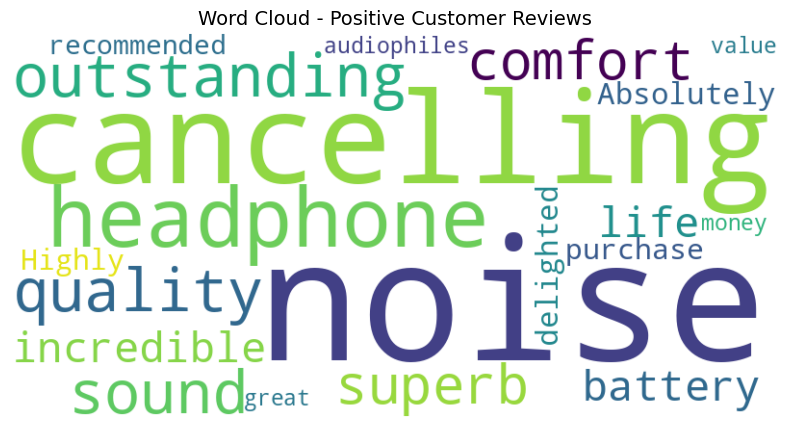

In [ ]:
from nltk.sentiment.vader import SentimentIntensityAnalyzer
from wordcloud import WordCloud

reviews = [
    "This noise-cancelling headphone has outstanding sound quality, superb comfort, and incredible battery life!",
    "The delivery arrived on Tuesday and the package contained standard black cables.",
    "Terrible customer service, pathetic build quality, and the device stopped working after two days.",
    "Absolutely delighted with this purchase! Highly recommended for audiophiles and great value for money.",
    "Disappointing performance, sluggish interface, and completely overpriced for what it offers."
]

sia = SentimentIntensityAnalyzer()
review_results = []

for r in reviews:
    scores = sia.polarity_scores(r)
    compound = scores['compound']
    if compound >= 0.05:
        label = 'Positive'
    elif compound <= -0.05:
        label = 'Negative'
    else:
        label = 'Neutral'

    review_results.append({
        'Review': r,
        'Compound Score': compound,
        'Pos': scores['pos'],
        'Neg': scores['neg'],
        'Classification': label
    })

rev_df = pd.DataFrame(review_results)
print("--- Sentiment Classification Results ---")
print(rev_df[['Review', 'Compound Score', 'Classification']].to_string(index=False))

# 3. Word Cloud for positive reviews
pos_texts = " ".join([r['Review'] for r in review_results if r['Classification'] == 'Positive'])
wordcloud = WordCloud(width=800, height=400, background_color='white', colormap='viridis').generate(pos_texts)

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Word Cloud - Positive Customer Reviews', fontsize=14)
plt.show()

---
### Q6: Text Generation using Deep Learning (LSTM / Dense)
**Tasks:**
1. Tokenize paragraph (~100 words) using `Tokenizer()` from `keras.preprocessing.text`
2. Create input sequences and build an LSTM or Dense model
3. Train model and generate 2-3 new lines starting from a seed word.

In [ ]:
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout

# Paragraph (~100 words)
corpus = """
Deep learning is a subset of machine learning based on artificial neural networks with representation learning.
Learning can be supervised semi-supervised or unsupervised in nature.
Deep learning architectures such as deep neural networks recurrent neural networks and convolutional neural networks
have been applied to fields including computer vision speech recognition natural language processing audio recognition
social network filtering machine translation bioinformatics drug design medical image analysis and climate science.
These neural networks learn representations of data with multiple levels of abstraction allowing computers to build
complex concepts out of simpler concepts.
"""

# 1. Tokenize text using Keras Tokenizer
tokenizer = Tokenizer()
tokenizer.fit_on_texts([corpus])
total_words = len(tokenizer.word_index) + 1
print(f"Total unique vocabulary words: {total_words}")

# 2. Create n-gram input sequences
input_sequences = []
for line in corpus.strip().split('\n'):
    token_list = tokenizer.texts_to_sequences([line])[0]
    for i in range(1, len(token_list)):
        n_gram_sequence = token_list[:i+1]
        input_sequences.append(n_gram_sequence)

max_sequence_len = max([len(x) for x in input_sequences])
input_sequences = np.array(pad_sequences(input_sequences, maxlen=max_sequence_len, padding='pre'))

# Predictors and labels
X = input_sequences[:, :-1]
y = input_sequences[:, -1]
y = tf.keras.utils.to_categorical(y, num_classes=total_words)

# Build LSTM Model
model = Sequential([
    Embedding(total_words, 64, input_length=max_sequence_len - 1),
    LSTM(100),
    Dropout(0.2),
    Dense(total_words, activation='softmax')
])

model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
model.summary()

# Train model
history = model.fit(X, y, epochs=120, verbose=0)
print(f"Model trained successfully! Final training accuracy: {history.history['accuracy'][-1]:.4f}")

# 3. Text Generation Function
def generate_text(seed_text, next_words, model, max_seq_len):
    output_text = seed_text
    for _ in range(next_words):
        token_list = tokenizer.texts_to_sequences([output_text])[0]
        token_list = pad_sequences([token_list], maxlen=max_seq_len - 1, padding='pre')
        predicted_probs = model.predict(token_list, verbose=0)[0]
        predicted_idx = np.argmax(predicted_probs)

        output_word = ""
        for word, index in tokenizer.word_index.items():
            if index == predicted_idx:
                output_word = word
                break
        output_text += " " + output_word
    return output_text

# Generate 2-3 lines from seed words
seeds = ["deep learning", "neural networks", "computer vision"]
print("\n--- Generated Text Sequences ---")
for seed in seeds:
    generated = generate_text(seed, 10, model, max_sequence_len)
    print(f"\nSeed: '{seed}'")
    print(f"Generated line: {generated}")


Total unique vocabulary words: 69


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Model trained successfully! Final training accuracy: 0.8588

--- Generated Text Sequences ---

Seed: 'deep learning'
Generated line: deep learning architectures such as deep neural networks recurrent neural networks and

Seed: 'neural networks'
Generated line: neural networks learn learn of of data with multiple levels of abstraction

Seed: 'computer vision'
Generated line: computer vision been applied to fields including vision speech speech recognition natural
